# 08 — Linear vs Logistic Regression

> Same weighted sum, different question: how the two models are alike, where they part ways, and how to choose.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

Lessons 01–04 used linear regression; lesson 07 introduced logistic regression.
They share a name, a formula, and even a training algorithm — which makes them
easy to confuse. This lesson puts them side by side, on the same data, and
checks every claim with code.

**Contents**

1. The problem
2. Intuition — one picture of each
3. The mathematics — side by side
4. The data
5. Modeling — the experiments
6. Results and interpretation — when to use which
7. References

## 1. The problem

The question is not "which model is better?" — they answer different questions.

- **Linear regression** answers *how much?* — how many grams of CO2, how many
  Toman, how many dollars. The answer is a number on a continuous scale.
- **Logistic regression** answers *how likely?* — how likely is this customer
  to leave, this email to be spam, this patient to respond. The answer is a
  probability between 0 and 1, which becomes a yes/no by choosing a threshold.

The name "logistic *regression*" is a historical accident: it is a
**classification** model. The confusion is understandable, because under the
hood the two share almost everything. This lesson shows exactly what they share,
exactly where they differ, and what goes wrong if you use linear regression for
a yes/no question.

### At a glance

| | Linear regression | Logistic regression |
|---|---|---|
| **Question** | How much? | How likely? |
| **Target** | A number (price, emissions) | A category, usually 0 / 1 |
| **Output** | Any number, $-\infty$ to $+\infty$ | A probability, 0 to 1 |
| **Model** | $\hat{y} = b + \mathbf{w} \cdot \mathbf{x}$ | $p = \sigma(b + \mathbf{w} \cdot \mathbf{x})$ |
| **Shape** | Straight line (plane) | S-curve |
| **Cost** | Mean squared error | Log loss |
| **Fitting** | Exact formula *or* gradient descent | Gradient descent (no formula exists) |
| **A weight means** | Units of $y$ per unit of $x$ | Odds multiplied by $e^{w}$ per unit of $x$ |
| **Judged by** | MAE, RMSE, R² | Accuracy, precision, recall, log loss |
| **Seen in** | Lessons 01–04 | Lesson 07 |

Every row of this table is demonstrated below.

## 2. Intuition — one picture of each

Both models start by computing the same thing: a **weighted sum of the
features**, a score. The difference is what they do with it.

- Linear regression **uses the score as the answer.** The score is the
  prediction.
- Logistic regression **squashes the score** through the sigmoid, so it can only
  land between 0 and 1, and reads it as a probability.

So a linear model draws a straight line through the data, and a logistic model
draws an S-curve. When the target is a number, a straight line is natural. When
the target is 0 or 1, the data sit on two horizontal rows — and a straight line
through two rows of points has nowhere sensible to go.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the train/test split and the made-up example are the same on
# every run, and the numbers in README.md are the numbers you get.
RANDOM_SEED = 4


def sigmoid(z):
    return 1 / (1 + np.exp(-z))

## 3. The mathematics — side by side

**The model.** Identical first step, one extra step for logistic:

| | Linear | Logistic |
|---|---|---|
| Score | $z = b + \mathbf{w} \cdot \mathbf{x}$ | $z = b + \mathbf{w} \cdot \mathbf{x}$ |
| Prediction | $\hat{y} = z$ | $p = \sigma(z) = \dfrac{1}{1 + e^{-z}}$ |

**The cost.** This is where they genuinely differ.

$$
\text{Linear (mean squared error):} \quad J = \frac{1}{2m} \sum_{i=1}^{m} \big(\hat{y}^{(i)} - y^{(i)}\big)^2
$$

$$
\text{Logistic (log loss):} \quad J = -\frac{1}{m} \sum_{i=1}^{m} \Big[ y^{(i)} \log p^{(i)} + \big(1 - y^{(i)}\big) \log\big(1 - p^{(i)}\big) \Big]
$$

(The $\frac{1}{2}$ in front of the squared error is a convention that makes the
next formula tidier; it does not change where the minimum is.)

Squared error asks *how far off was the number?* Log loss asks *how much
probability did you give to what really happened?* Section 5 plots both, and
shows why squared error is the wrong judge of a probability.

**The slope.** Here is the surprise. Work out the gradient of each cost and you
get — for both models —

$$
\frac{\partial J}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} \big(\text{prediction}^{(i)} - y^{(i)}\big) \, x_j^{(i)}
$$

**error × input**, averaged. The same formula, letter for letter. The only
difference is what "prediction" means: the raw score for linear, the squashed
score for logistic. So the gradient descent loop from lesson 07 trains **both**
models, if you change one line. Section 5 does exactly that.

**Solving it.** For linear regression, setting that slope to zero gives equations
that can be solved directly (the *normal equations*), which is what
`LinearRegression().fit()` does. For logistic regression the sigmoid sits inside
the equations and no direct solution exists, so the search is the only way.

## 4. The data

The telecom churn dataset from lesson 07, with its own copy in this lesson's
`data/` folder: 200 customers, and a target `churn` that is 1 if the customer
left and 0 if they stayed. It is a yes/no question — logistic regression's home
ground — which makes it the right place to see what linear regression does when
it is asked the wrong kind of question.

In [2]:
df = pd.read_csv("data/ChurnData.csv")

feature_cols = ["tenure", "age", "address", "income", "ed", "employ", "equip"]
X = df[feature_cols].to_numpy(dtype=float)
y = df["churn"].astype(int).to_numpy()

print(df.shape)
print(f"churned: {y.sum()} of {len(y)}")

(200, 28)
churned: 58 of 200


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)

scaler = StandardScaler().fit(X_train)  # fitted on the training rows only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train set:", X_train.shape, "  Test set:", X_test.shape)

Train set: (160, 7)   Test set: (40, 7)


## 5. Modeling — the experiments

### Experiment 1: both models on one feature

Tenure alone, so the whole model fits on one chart. Each dot is a customer:
the bottom row stayed, the top row churned.

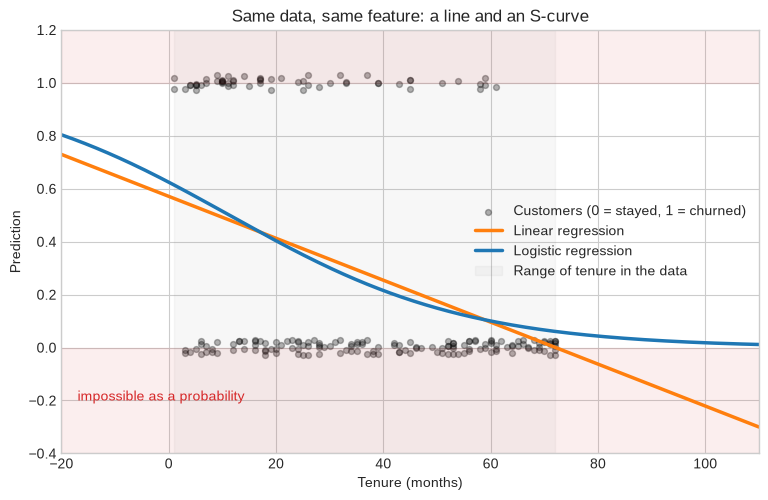

In [4]:
from sklearn.linear_model import LinearRegression, LogisticRegression

tenure = df[["tenure"]].to_numpy(dtype=float)

lin_1d = LinearRegression().fit(tenure, y)
log_1d = LogisticRegression(C=1e10).fit(tenure, y)  # huge C = no penalty, plain logistic regression

t_line = np.linspace(-20, 110, 300).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(9, 5.5))
jitter = np.random.default_rng(RANDOM_SEED).uniform(-0.03, 0.03, len(y))
ax.scatter(tenure, y + jitter, color="black", alpha=0.3, s=18, label="Customers (0 = stayed, 1 = churned)")
ax.plot(t_line, lin_1d.predict(t_line), color="tab:orange", linewidth=2.5, label="Linear regression")
ax.plot(t_line, log_1d.predict_proba(t_line)[:, 1], color="tab:blue", linewidth=2.5, label="Logistic regression")
ax.axhspan(-0.5, 0, color="tab:red", alpha=0.08)
ax.axhspan(1, 1.5, color="tab:red", alpha=0.08)
ax.axvspan(tenure.min(), tenure.max(), color="grey", alpha=0.06, label="Range of tenure in the data")
ax.annotate("impossible as a probability", (-17, -0.2), color="tab:red")
ax.set_xlim(-20, 110)
ax.set_ylim(-0.4, 1.2)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Prediction")
ax.set_title("Same data, same feature: a line and an S-curve")
ax.legend(loc="center right")

# Saved so README.md can show the result without anyone running this notebook.
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
for months in [1, 36, 72, 100]:
    print(
        f"tenure {months:>3} months:  linear says {lin_1d.predict([[months]])[0]:+.3f}   "
        f"logistic says {log_1d.predict_proba([[months]])[0, 1]:.3f}"
    )

tenure   1 months:  linear says +0.563   logistic says 0.614
tenure  36 months:  linear says +0.286   logistic says 0.247
tenure  72 months:  linear says +0.001   logistic says 0.061
tenure 100 months:  linear says -0.221   logistic says 0.018


Inside the data the two curves are not far apart. The difference is at the
edges. The straight line keeps going: a customer who has stayed 100 months gets
a churn "probability" below zero. The S-curve bends and flattens, approaching 0
but never crossing it. A probability of −0.2 is not a cautious estimate; it is
not a probability at all.

### Experiment 2: all seven features

On one feature the line only misbehaves at the edges. With seven, customers can
be extreme in several directions at once.

In [6]:
from sklearn import metrics

lin = LinearRegression().fit(X_train_s, y_train)
log = LogisticRegression(C=1e10, max_iter=10_000).fit(X_train_s, y_train)

lin_all = lin.predict(np.vstack([X_train_s, X_test_s]))
log_all = log.predict_proba(np.vstack([X_train_s, X_test_s]))[:, 1]

print(f"Linear:   predictions from {lin_all.min():+.3f} to {lin_all.max():+.3f};  "
      f"{(lin_all < 0).sum()} of 200 customers below 0, {(lin_all > 1).sum()} above 1")
print(f"Logistic: predictions from {log_all.min():+.3f} to {log_all.max():+.3f};  always inside 0–1")

Linear:   predictions from -0.201 to +0.694;  29 of 200 customers below 0, 0 above 1
Logistic: predictions from +0.004 to +0.824;  always inside 0–1


In [7]:
lin_test = lin.predict(X_test_s)
log_test = log.predict_proba(X_test_s)[:, 1]

print("Turning each into a yes/no at 0.5:")
print(f"  linear   accuracy {metrics.accuracy_score(y_test, lin_test >= 0.5):.3f}")
print(f"  logistic accuracy {metrics.accuracy_score(y_test, log_test >= 0.5):.3f}")
print()
print("Judging them as probabilities (log loss, lower is better):")
print(f"  linear   {metrics.log_loss(y_test, np.clip(lin_test, 0.01, 0.99)):.3f}   (after forcing its output into 0.01–0.99)")
print(f"  logistic {metrics.log_loss(y_test, log_test):.3f}")

Turning each into a yes/no at 0.5:
  linear   accuracy 0.725
  logistic accuracy 0.725

Judging them as probabilities (log loss, lower is better):
  linear   0.667   (after forcing its output into 0.01–0.99)
  logistic 0.636


An honest result: as a **yes/no** classifier at a 0.5 cut-off, linear regression
does just as well here — the same 29 of 40. The line and the S-curve cross 0.5 in
similar places, so they put most customers on the same side.

The gap is in the **probabilities**. Linear regression's outputs have to be
forced into range before log loss can even be computed, and even then they are
worse. If all you ever wanted was a yes/no at 0.5, the line can get away with it
on data like this. If you want to rank customers by risk, choose a threshold, or
tell a retention team "70% likely" — which was the whole point in lesson 07 —
you need numbers that behave like probabilities.

The next experiment shows the line can fail at yes/no too.

### Experiment 3: when more obvious data makes the line worse

A small made-up example, where the answer is known. Forty points with one
feature $x$ from 0 to 10: below 5 the answer is mostly 0, above 5 mostly 1, with
three points flipped to add some noise. Both models should put their boundary —
where the prediction crosses 0.5 — near 5.

Then add five more points far out to the right, at $x$ = 30–40, all labelled 1.
These are the **easiest** points imaginable: far past the boundary, and on the
right side of it. A good model should barely notice them.

In [8]:
rng = np.random.default_rng(0)
x_toy = rng.uniform(0, 10, 40)
y_toy = (x_toy > 5).astype(int)
flipped = rng.choice(40, 3, replace=False)
y_toy[flipped] = 1 - y_toy[flipped]

x_extra = np.array([30, 32, 35, 38, 40])
x_more = np.concatenate([x_toy, x_extra])
y_more = np.concatenate([y_toy, np.ones(5, dtype=int)])


def boundaries(x, y):
    # Where each model's prediction crosses 0.5.
    L = LinearRegression().fit(x.reshape(-1, 1), y)
    G = LogisticRegression(C=1e10).fit(x.reshape(-1, 1), y)
    return L, G, (0.5 - L.intercept_) / L.coef_[0], -G.intercept_[0] / G.coef_[0, 0]


L0, G0, lin_b0, log_b0 = boundaries(x_toy, y_toy)
L1, G1, lin_b1, log_b1 = boundaries(x_more, y_more)


def acc_on_original(model_pred):
    return (model_pred == y_toy).mean()


summary = pd.DataFrame(
    {
        "linear boundary": [lin_b0, lin_b1],
        "logistic boundary": [log_b0, log_b1],
        "linear accuracy on the 40": [
            acc_on_original(L0.predict(x_toy.reshape(-1, 1)) >= 0.5),
            acc_on_original(L1.predict(x_toy.reshape(-1, 1)) >= 0.5),
        ],
        "logistic accuracy on the 40": [
            acc_on_original(G0.predict(x_toy.reshape(-1, 1))),
            acc_on_original(G1.predict(x_toy.reshape(-1, 1))),
        ],
    },
    index=["40 points", "40 points + 5 easy ones"],
)
summary.round(3)

,linear boundary,logistic boundary,linear accuracy on the 40,logistic accuracy on the 40
40 points,4.769,4.934,0.90,0.925
40 points + 5 easy ones,3.438,4.934,0.85,0.925


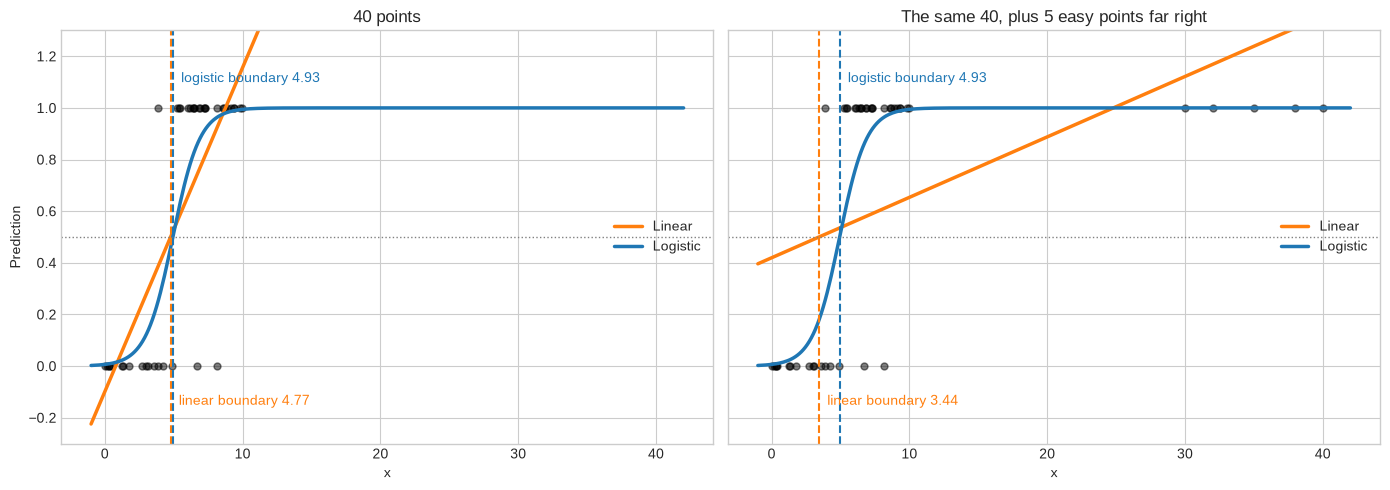

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
x_line = np.linspace(-1, 42, 300).reshape(-1, 1)

for ax, (x, yv, L, G, lb, gb, title) in zip(
    axes,
    [
        (x_toy, y_toy, L0, G0, lin_b0, log_b0, "40 points"),
        (x_more, y_more, L1, G1, lin_b1, log_b1, "The same 40, plus 5 easy points far right"),
    ],
):
    ax.scatter(x, yv, color="black", alpha=0.5, s=25)
    ax.plot(x_line, L.predict(x_line), color="tab:orange", linewidth=2.5, label="Linear")
    ax.plot(x_line, G.predict_proba(x_line)[:, 1], color="tab:blue", linewidth=2.5, label="Logistic")
    ax.axhline(0.5, color="grey", linestyle=":", linewidth=1)
    ax.axvline(lb, color="tab:orange", linestyle="--", linewidth=1.5)
    ax.axvline(gb, color="tab:blue", linestyle="--", linewidth=1.5)
    ax.annotate(f"linear boundary {lb:.2f}", (lb + 0.6, -0.15), color="tab:orange")
    ax.annotate(f"logistic boundary {gb:.2f}", (gb + 0.6, 1.1), color="tab:blue")
    ax.set_ylim(-0.3, 1.3)
    ax.set_xlabel("x")
    ax.set_title(title)
    ax.legend(loc="center right")

axes[0].set_ylabel("Prediction")
plt.tight_layout()
plt.savefig("figures/outliers.png", dpi=150, bbox_inches="tight")
plt.show()

The five easy points **dragged the linear boundary from about 4.8 to 3.4**, and
now it misclassifies points it used to get right — its accuracy on the original
40 falls from 0.90 to 0.85. The logistic boundary does not move at all.

Why? Squared error cares about *distance*. Those far-right points sit well above
where the line would put them if it kept its old slope, so the line tilts to
reduce those big distances — and tilting moves the place it crosses 0.5.
Log loss cares about *probability*. The S-curve already gives those points a
probability of almost exactly 1, so they cost almost nothing and exert almost no
pull. **Being confidently right costs nothing under log loss, so it changes
nothing.**

### Experiment 4: the two costs, for one customer

A customer who **churned** ($y = 1$). How much does each cost charge, depending
on the prediction?

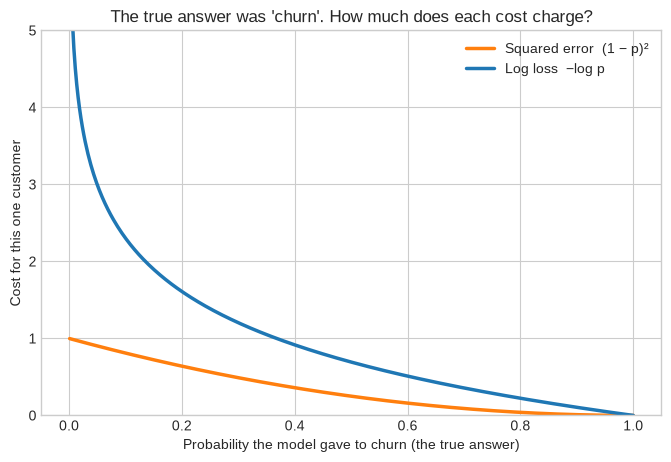

model said 0.9    squared error 0.010   log loss 0.105
model said 0.5    squared error 0.250   log loss 0.693
model said 0.1    squared error 0.810   log loss 2.303
model said 0.01   squared error 0.980   log loss 4.605


In [10]:
p = np.linspace(0.001, 1, 400)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(p, (1 - p) ** 2, color="tab:orange", linewidth=2.5, label="Squared error  (1 − p)²")
ax.plot(p, -np.log(p), color="tab:blue", linewidth=2.5, label="Log loss  −log p")
ax.set_xlabel("Probability the model gave to churn (the true answer)")
ax.set_ylabel("Cost for this one customer")
ax.set_ylim(0, 5)
ax.set_title("The true answer was 'churn'. How much does each cost charge?")
ax.legend()
plt.show()

for prob in [0.9, 0.5, 0.1, 0.01]:
    print(f"model said {prob:<5}  squared error {(1 - prob) ** 2:.3f}   log loss {-np.log(prob):.3f}")

Squared error can never charge more than 1, however wrong the model was: saying
1% to something that happened costs 0.98, barely more than saying 10% (0.81).
Log loss charges 4.6 for the 1% — it treats confident mistakes as the serious
failure they are for a model whose job is probabilities. That is why logistic
regression uses log loss, and why squared error is the wrong ruler for it.

### Experiment 5: one training loop for both

Section 3 claimed the gradient-descent update is the same for both models,
except for one line. Here is that loop, with the one line made into a switch.

In [11]:
def gradient_descent(X, y, squash, alpha=0.1, n_steps=5000):
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    for _ in range(n_steps):
        prediction = squash(X @ w + b)        # <- the only line that differs
        error = prediction - y
        w = w - alpha * (X.T @ error) / m     # identical for both: error × input
        b = b - alpha * error.mean()
    return w, b


def no_squash(z):
    return z  # linear regression: the score is the answer


w_lin, b_lin = gradient_descent(X_train_s, y_train, squash=no_squash)
w_log, b_log = gradient_descent(X_train_s, y_train, squash=sigmoid, alpha=1.0)

pd.DataFrame(
    {
        "linear: our loop": np.append(w_lin, b_lin),
        "linear: scikit-learn": np.append(lin.coef_, lin.intercept_),
        "logistic: our loop": np.append(w_log, b_log),
        "logistic: scikit-learn": np.append(log.coef_[0], log.intercept_[0]),
    },
    index=feature_cols + ["intercept b"],
).round(3)

,linear: our loop,linear: scikit-learn,logistic: our loop,logistic: scikit-learn
tenure,-0.129,-0.129,-0.915,-0.914
age,-0.021,-0.021,-0.184,-0.183
address,-0.001,-0.001,-0.119,-0.120
income,-0.000,-0.000,-0.006,-0.006
ed,-0.009,-0.009,0.052,0.051
employ,-0.026,-0.026,-0.239,-0.239
equip,0.135,0.135,0.794,0.794
intercept b,0.269,0.269,-1.520,-1.518


The same loop, with `squash=no_squash` or `squash=sigmoid`, reproduces **both**
of scikit-learn's models. The two methods really are one algorithm with one
line changed — and that line is the whole difference between predicting a
number and predicting a probability.

Note that the two sets of weights are *not* the same, even with the same
features and the same data: the squash changes what "error" means, so the loop
settles somewhere else. Linear weights are in units of "churn per standard
deviation" (a number that has no real meaning here); logistic weights are
changes in log-odds.

### Experiment 6: reading a weight

The same feature, tenure, in each model:

In [12]:
tenure_std = scaler.scale_[0]
lin_w = lin.coef_[0] / tenure_std       # per month, in the model's own units
log_w = log.coef_[0, 0] / tenure_std

print(f"Linear:   each extra month of tenure changes the prediction by {lin_w:+.4f}")
print(f"          i.e. 12 extra months → {12 * lin_w:+.3f} on a 0-to-1 scale, whatever the starting point")
print()
print(f"Logistic: each extra month multiplies the odds of churning by e^{log_w:.4f} = {np.exp(log_w):.3f}")
print(f"          i.e. 12 extra months → odds × {np.exp(12 * log_w):.3f}")

Linear:   each extra month of tenure changes the prediction by -0.0059
          i.e. 12 extra months → -0.071 on a 0-to-1 scale, whatever the starting point

Logistic: each extra month multiplies the odds of churning by e^-0.0419 = 0.959
          i.e. 12 extra months → odds × 0.604


A linear weight is **additive**: 12 more months subtracts the same amount from
the prediction whether the customer started at 0.9 or at 0.05 — which is how it
ends up below zero. A logistic weight is **multiplicative on the odds**: 12 more
months shrinks the odds by the same *factor* everywhere, so a customer already
at low risk only moves a little, and the probability can approach 0 without ever
reaching it.

## 6. Results and interpretation

### What the experiments showed

1. **Shared foundation.** Both compute the same weighted sum. The same
   gradient-descent loop trains both, and reproduces scikit-learn's weights for
   each — with one line changed.
2. **Different output.** Linear regression predicted "probabilities" below zero
   for 29 of the 200 customers; logistic regression can only produce values
   between 0 and 1.
3. **Yes/no at 0.5 — sometimes a tie.** On the churn data both reached the same
   test accuracy. Treating a line as a classifier does not always fail loudly.
4. **Probabilities — logistic wins.** Linear outputs had to be forced into range
   before they could be scored as probabilities, and still scored worse.
5. **Robustness — logistic wins.** Five easy, correctly labelled points dragged
   the linear boundary and lowered its accuracy; the logistic boundary did not
   move.
6. **The cost is the real difference.** Squared error caps its penalty at 1 and
   cares about distance; log loss punishes confident mistakes without limit and
   ignores confident successes.

### When to use which

| If the target is… | Use | Because |
|---|---|---|
| A number on a scale: price, weight, emissions, time | **Linear regression** | It predicts how much, in the target's own units |
| Yes / no: churn, spam, fraud, disease | **Logistic regression** | It predicts how likely, always as a valid probability |
| One of several categories | **Logistic regression** (multiclass) or a tree, KNN… | Categories have no "distance" between them for a line to measure |
| 0/1 but you are tempted to use a line because "it gets similar accuracy" | **Still logistic** | The line's probabilities are invalid, and far-away points can move its boundary |

### Common mistakes

- **Reading "logistic regression" as a regression model.** It predicts a
  category. Judge it with classification metrics — accuracy, precision, recall,
  log loss — never R².
- **Reading a logistic weight like a linear one.** It is not "change in
  probability per unit". It is the change in log-odds; $e^{w}$ is the odds
  multiplier.
- **Forgetting the threshold is a choice.** Linear regression's output *is* the
  answer. Logistic regression's output is a probability, and turning it into
  yes/no needs a threshold — 0.5 by default, but lesson 07 showed that a lower
  one can be far more useful.
- **Skipping scaling for gradient descent.** Both models train by gradient
  descent in this lesson, and both need standardised features for one learning
  rate to suit every direction.

## 7. References

- Course: Machine Learning with Python (Jadi) — lessons on linear and logistic
  regression, which this lesson draws together. The comparison and experiments
  are this repository's own.
- Dataset: `ChurnData.csv`, telecom customer churn records, as supplied with the
  course.
- scikit-learn documentation: [Ordinary least squares](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares)
- scikit-learn documentation: [Logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)